# Seasonal Product Demand Analysis

Course: Exploratory Data Analysis and Visualization (EDAV — 22ADC31N)  
Dataset: UCI Online Retail II  
Primary objective: identify individual retail products whose peak monthly quantity repeats across comparable months in 2010 and 2011.

This notebook follows a question-wise EDAV structure inspired by the clear Q1–Q5 organization in the course sample. All findings are derived from the dataset and the displayed code. The primary product comparison uses January–November 2010 versus January–November 2011. December is excluded from the primary comparison because the available transaction records end before the end of each December.

The screening identifies recurring-peak candidates, not statistically proven long-term seasonal products.

In [ ]:
import pandas as pd
import urllib.request
import os

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00502/online_retail_II.xlsx"
file_path = "/content/online_retail_II.xlsx"

print("Downloading dataset...")

urllib.request.urlretrieve(url, file_path)

print("Download complete!")
print("File size:", round(os.path.getsize(file_path) / (1024**2), 2), "MB")

excel_file = pd.ExcelFile(file_path)
print("Available sheets:", excel_file.sheet_names)

Download complete!
File size: 43.51 MB
Available sheets: ['Year 2009-2010', 'Year 2010-2011']


In [ ]:
# Load both sheets from the Excel workbook
sheet_1 = pd.read_excel(file_path, sheet_name="Year 2009-2010")
sheet_2 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

# Combine both years into one DataFrame
df = pd.concat([sheet_1, sheet_2], ignore_index=True)

# Inspect the dataset
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset shape: (1067371, 8)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

First five rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## Setup: Initial Data Quality Audit

Inspect the raw data types, missing values, duplicate rows, date coverage, quantity and price anomalies, cancellation-coded invoice records, and dataset cardinalities before cleaning.

In [ ]:
# 1. Check column data types
print("DATA TYPES")
print(df.dtypes)

# 2. Check missing values
print("\nMISSING VALUES")
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})
display(missing)

# 3. Check duplicate rows
print("\nDUPLICATE ROWS")
print("Duplicate count:", df.duplicated().sum())

# 4. Check transaction dates
print("\nDATE RANGE")
print("First transaction:", df["InvoiceDate"].min())
print("Last transaction:", df["InvoiceDate"].max())

# 5. Check quantities and prices
print("\nQUANTITY AND PRICE")
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())
print("Negative prices:", (df["Price"] < 0).sum())
print("Zero prices:", (df["Price"] == 0).sum())

# 6. Check cancelled invoices
print("\nCANCELLED INVOICES")
cancelled = df["Invoice"].astype(str).str.startswith("C")
print("Rows with cancellation invoice codes:", cancelled.sum())

# 7. Count unique products, invoices and countries
print("\nDATASET OVERVIEW")
print("Unique products:", df["StockCode"].nunique())
print("Unique invoices:", df["Invoice"].nunique())
print("Unique countries:", df["Country"].nunique())

DATA TYPES
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

MISSING VALUES


,Missing Count,Missing Percentage
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00



DUPLICATE ROWS
Duplicate count: 34335

DATE RANGE
First transaction: 2009-12-01 07:45:00
Last transaction: 2011-12-09 12:50:00

QUANTITY AND PRICE
Negative quantities: 22950
Zero quantities: 0
Negative prices: 5
Zero prices: 6202

CANCELLED INVOICES
Rows with cancellation invoice codes: 19494

DATASET OVERVIEW
Unique products: 5305
Unique invoices: 53628
Unique countries: 43


## Setup: Data Cleaning and Preparation

The following cleaning steps are applied sequentially: exact duplicate removal, cancellation-coded invoice removal, non-positive quantity removal, negative-price removal, and removal of missing product descriptions. Customer IDs are retained when missing, and zero-price records that remain after cleaning are kept for quantity analysis.

In [ ]:
# Keep the original dataset unchanged
df_clean = df.copy()

original_rows = len(df_clean)

# Step 1: Remove exact duplicate rows
duplicates_removed = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().copy()

# Step 2: Remove cancelled invoices
cancelled_mask = (
    df_clean["Invoice"]
    .astype(str)
    .str.strip()
    .str.startswith("C")
)

cancelled_removed = cancelled_mask.sum()
df_clean = df_clean.loc[~cancelled_mask].copy()

# Step 3: Remove non-positive quantities
invalid_quantity_mask = df_clean["Quantity"] <= 0
quantity_removed = invalid_quantity_mask.sum()
df_clean = df_clean.loc[~invalid_quantity_mask].copy()

# Step 4: Remove negative prices
negative_price_mask = df_clean["Price"] < 0
negative_prices_removed = negative_price_mask.sum()
df_clean = df_clean.loc[~negative_price_mask].copy()

# Step 5: Remove rows with missing product descriptions
missing_description_mask = df_clean["Description"].isna()
missing_descriptions_removed = missing_description_mask.sum()
df_clean = df_clean.loc[~missing_description_mask].copy()

# Step 6: Calculate transaction revenue
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]

# Step 7: Display cleaning summary
print("DATA CLEANING SUMMARY")
print("-" * 40)
print("Original rows:", original_rows)
print("Exact duplicates removed:", duplicates_removed)
print("Cancelled invoice rows removed:", cancelled_removed)
print("Non-positive quantity rows removed:", quantity_removed)
print("Negative price rows removed:", negative_prices_removed)
print("Missing descriptions removed:", missing_descriptions_removed)
print("Final cleaned rows:", len(df_clean))

print("\nCLEANED DATA PREVIEW")
display(df_clean.head())

print("\nRemaining missing values:")
display(df_clean.isnull().sum())

DATA CLEANING SUMMARY
----------------------------------------
Original rows: 1067371
Exact duplicates removed: 34335
Cancelled invoice rows removed: 19104
Non-positive quantity rows removed: 3393
Negative price rows removed: 5
Missing descriptions removed: 1642
Final cleaned rows: 1008892

CLEANED DATA PREVIEW


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0



Remaining missing values:


,0
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
Price,0
Customer ID,229397
Country,0
Revenue,0


In [ ]:
# Setup: Create date features and the overall monthly demand summary

df_clean["Year"] = df_clean["InvoiceDate"].dt.year
df_clean["Month"] = df_clean["InvoiceDate"].dt.month
df_clean["Month_Name"] = df_clean["InvoiceDate"].dt.month_name()
df_clean["Date"] = df_clean["InvoiceDate"].dt.normalize()

daily = df_clean.groupby("Date").agg(
    Daily_Units=("Quantity", "sum"),
    Daily_Revenue=("Revenue", "sum"),
    Daily_Orders=("Invoice", "nunique")
)

# Fill missing dates for the daily series; December months are not used
# in the primary year-over-year comparison because coverage is partial.
daily = daily.asfreq("D", fill_value=0)
daily["Year"] = daily.index.year
daily["Month"] = daily.index.month
daily["YearMonth"] = daily.index.to_period("M").astype(str)

monthly = daily.groupby(["Year", "Month", "YearMonth"]).agg(
    Total_Units=("Daily_Units", "sum"),
    Total_Revenue=("Daily_Revenue", "sum"),
    Total_Orders=("Daily_Orders", "sum"),
    Average_Units_Per_Day=("Daily_Units", "mean"),
    Active_Days=("Daily_Units", lambda x: (x > 0).sum()),
    Calendar_Days=("Daily_Units", "size")
).reset_index()

print("MONTHLY DEMAND SUMMARY")
display(monthly)
print("\nHIGHEST MONTHLY UNIT TOTALS (RAW MONTHLY VIEW; DECEMBER COVERAGE IS PARTIAL)")
display(
    monthly.sort_values("Total_Units", ascending=False)
    [["YearMonth", "Total_Units", "Total_Revenue"]].head(10)
)

MONTHLY DEMAND SUMMARY


,Year,Month,YearMonth,Total_Units,Total_Revenue,Total_Orders,Average_Units_Per_Day,Active_Days,Calendar_Days
0,2009,12,2009-12,425511,822483.950,1682,13726.161290,21,31
1,2010,1,2010-01,391864,651155.112,1106,12640.774194,24,31
2,2010,2,2010-02,382297,551504.726,1203,13653.464286,24,28
3,2010,3,2010-03,527631,830915.261,1687,17020.354839,27,31
4,2010,4,2010-04,370752,678875.252,1464,12358.400000,23,30
5,2010,5,2010-05,407447,657705.500,1504,13143.451613,24,31
6,2010,6,2010-06,411682,749537.310,1652,13722.733333,26,30
7,2010,7,2010-07,338456,648810.270,1534,10917.935484,26,31
8,2010,8,2010-08,474397,695251.910,1427,15303.129032,26,31
9,2010,9,2010-09,585311,921696.991,1845,19510.366667,26,30



HIGHEST MONTHLY UNIT TOTALS (RAW MONTHLY VIEW; DECEMBER COVERAGE IS PARTIAL)


,YearMonth,Total_Units,Total_Revenue
23,2011-11,766844,1503866.780
11,2010-11,726108,1464293.142
22,2011-10,624545,1151263.730
10,2010-10,620642,1161902.220
9,2010-09,585311,921696.991
21,2011-09,571399,1056435.192
3,2010-03,527631,830915.261
8,2010-08,474397,695251.910
0,2009-12,425511,822483.950
20,2011-08,422328,757841.380


In [ ]:
# Verify recorded transaction coverage for each December
import pandas as pd

for month in ["2009-12", "2010-12", "2011-12"]:
    period = pd.Period(month, freq="M")

    records = df.loc[
        df["InvoiceDate"].dt.to_period("M") == period
    ]

    print(f"\n{month}")
    print("First recorded transaction:", records["InvoiceDate"].min())
    print("Last recorded transaction:", records["InvoiceDate"].max())
    print("Distinct transaction dates:", records["InvoiceDate"].dt.date.nunique())
    print("Transaction rows:", len(records))


2009-12
First recorded transaction: 2009-12-01 07:45:00
Last recorded transaction: 2009-12-23 16:58:00
Distinct transaction dates: 21
Transaction rows: 45228

2010-12
First recorded transaction: 2010-12-01 08:26:00
Last recorded transaction: 2010-12-23 17:41:00
Distinct transaction dates: 20
Transaction rows: 65004

2011-12
First recorded transaction: 2011-12-01 08:12:00
Last recorded transaction: 2011-12-09 12:50:00
Distinct transaction dates: 8
Transaction rows: 25526


In [ ]:
# Audit product codes that differ only by capitalization

audit_df = df_clean.assign(
    Original_Code=df_clean["StockCode"].astype(str).str.strip(),
    Normalized_Code=df_clean["StockCode"].astype(str).str.strip().str.upper(),
    Description_Normalized=(
        df_clean["Description"].astype("string").str.strip().str.upper()
        .str.replace(r"\s+", " ", regex=True)
    )
)

code_audit = audit_df.groupby("Normalized_Code").agg(
    Original_Codes=("Original_Code", lambda s: sorted(s.unique().tolist())),
    Variant_Count=("Original_Code", "nunique"),
    Description_Count=("Description_Normalized", "nunique"),
    Descriptions=("Description_Normalized", lambda s: sorted(s.dropna().astype(str).unique().tolist()))
).reset_index()

variants = code_audit[code_audit["Variant_Count"] > 1].copy()
safe_codes = code_audit.loc[
    (code_audit["Variant_Count"] > 1) &
    (code_audit["Description_Count"] == 1),
    "Normalized_Code"
].tolist()
conflicting_codes = code_audit.loc[
    (code_audit["Variant_Count"] > 1) &
    (code_audit["Description_Count"] > 1),
    "Normalized_Code"
].tolist()

print("Stock-code groups with capitalization variants:", len(variants))
print("Groups eligible for consolidation under the matching-description rule:", len(safe_codes))
print("Groups retained separately because descriptions conflict:", len(conflicting_codes))
print("\nExamples of conflicting-description groups (first 15):")
display(
    variants[variants["Description_Count"] > 1]
    [["Normalized_Code", "Original_Codes", "Description_Count", "Descriptions"]]
    .head(15)
)

Stock-code groups with capitalization variants: 171
Groups eligible for consolidation under the matching-description rule: 127
Groups retained separately because descriptions conflict: 44

Examples of conflicting-description groups (first 15):


,Normalized_Code,Original_Codes,Description_Count,Descriptions
3005,37482P,"[37482P, 37482p]",2,"[CUBIC MUG PINK POLKA DOT, CUBIC MUG PINK POLK..."
3125,47556B,"[47556B, 47556b]",2,"[DID A CREDIT AND DID NOT TICK RET, TEA TIME T..."
3131,47566B,"[47566B, 47566b]",3,"[CORRECT PREVIOUS ADJUSTMENT, INCORRECTLY CRED..."
3152,47591B,"[47591B, 47591b]",2,"[SCOTTIES CHILDRENS APRON, SCOTTIES DES CHILD'..."
3153,47591C,"[47591C, 47591c]",2,"[BLUE FAIRY CAKE CHILD'S APRON, BLUE FAIRY CAK..."
3154,47591D,"[47591D, 47591d]",2,"[PINK FAIRY CAKE CHILD'S APRON, PINK FAIRY CAK..."
3157,47593A,"[47593A, 47593a]",3,"[CAROUSEL DESIGN BABY BIB, CAROUSEL PONIES BAB..."
3158,47593B,"[47593B, 47593b]",2,"[SCOTTIE DOGS BABY BIB, SCOTTIES DESIGN BABY BIB]"
3171,48173C,"[48173C, 48173c]",3,"[DAMAGED, DOOR MAT BLACK FLOCK, DOORMAT BLACK ..."
3313,72801C,"[72801C, 72801c]",2,"[4 ROSE PINK DINNER CANDLES, S/4 ROSE PINK DIN..."


In [ ]:
# Prepare consistent product keys without overwriting original stock codes

work = df_clean.copy()
work["Original_Code"] = work["StockCode"].astype(str).str.strip()
work["Normalized_Code"] = work["Original_Code"].str.upper()
work["Description_Normalized"] = (
    work["Description"].astype("string").str.strip().str.upper()
    .str.replace(r"\s+", " ", regex=True)
)

work["ProductKey"] = work["Original_Code"]
safe_mask = work["Normalized_Code"].isin(safe_codes)
work.loc[safe_mask, "ProductKey"] = work.loc[safe_mask, "Normalized_Code"]

# Explicitly derive the year/month fields used in all downstream analyses.
work["Year"] = work["InvoiceDate"].dt.year
work["Month"] = work["InvoiceDate"].dt.month

print("Rows prepared for product analysis:", len(work))
print("Product keys after selective capitalization harmonization:", work["ProductKey"].nunique())
print("Original StockCode values are preserved in the dataset.")
print("Only case variants with a single normalized description are consolidated.")

Rows prepared for product analysis: 1008892
Product keys after selective capitalization harmonization: 4793
Original StockCode values are preserved in the dataset.
Only case variants with a single normalized description are consolidated.


## Q1. NumPy — Statistical Analysis of Monthly Retail Demand [CO1, BL3]

Question: How does monthly unit demand vary across January–November 2010 and the same months in 2011?

Concepts: Convert monthly totals to NumPy arrays and calculate mean, median, minimum, maximum and standard deviation. These statistics summarize the 11 comparable monthly totals for each year; they are not transaction-level statistics.

In [ ]:
# Q1: NumPy — Monthly retail-demand statistics [CO1, BL3]

import numpy as np
import pandas as pd

q1_data = df_clean[
    df_clean["Year"].isin([2010, 2011]) &
    df_clean["Month"].between(1, 11)
].copy()

# One value per month: total units sold in that month.
monthly_units_q1 = (
    q1_data.groupby(["Year", "Month"])["Quantity"]
    .sum()
    .unstack("Year")
    .reindex(index=range(1, 12), columns=[2010, 2011], fill_value=0)
)

month_names_q1 = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov"
]
monthly_units_q1.index = month_names_q1

summary_rows = []
for year in [2010, 2011]:
    values = monthly_units_q1[year].to_numpy(dtype=np.float64)
    summary_rows.append({
        "Year": year,
        "Mean monthly units": round(float(np.mean(values)), 2),
        "Median monthly units": round(float(np.median(values)), 2),
        "Minimum monthly units": int(np.min(values)),
        "Maximum monthly units": int(np.max(values)),
        "Standard deviation": round(float(np.std(values)), 2)
    })

q1_summary = pd.DataFrame(summary_rows)
print("NUMPY SUMMARY OF THE 11 COMPARABLE MONTHLY UNIT TOTALS")
display(q1_summary)
print("\nMonthly totals used in the statistics:")
display(monthly_units_q1)

NUMPY SUMMARY OF THE 11 COMPARABLE MONTHLY UNIT TOTALS


,Year,Mean monthly units,Median monthly units,Minimum monthly units,Maximum monthly units,Standard deviation
0,2010,476053.36,411682.0,338456,726108,117853.32
1,2011,448996.27,397099.0,283041,766844,138491.04



Monthly totals used in the statistics:


Year,2010,2011
Jan,391864,387366
Feb,382297,283041
Mar,527631,380158
Apr,370752,309418
May,407447,397099
Jun,411682,392822
Jul,338456,403939
Aug,474397,422328
Sep,585311,571399
Oct,620642,624545


## Q2. Pandas — Monthly Sales Quantity and Revenue [CO2, BL3]

Question: Which months record the highest quantities and revenue, and how do these measures compare between 2010 and 2011?

Concepts: Date-based selection, `pivot_table`, aggregation and visual comparison. The primary heatmaps use January–November only.

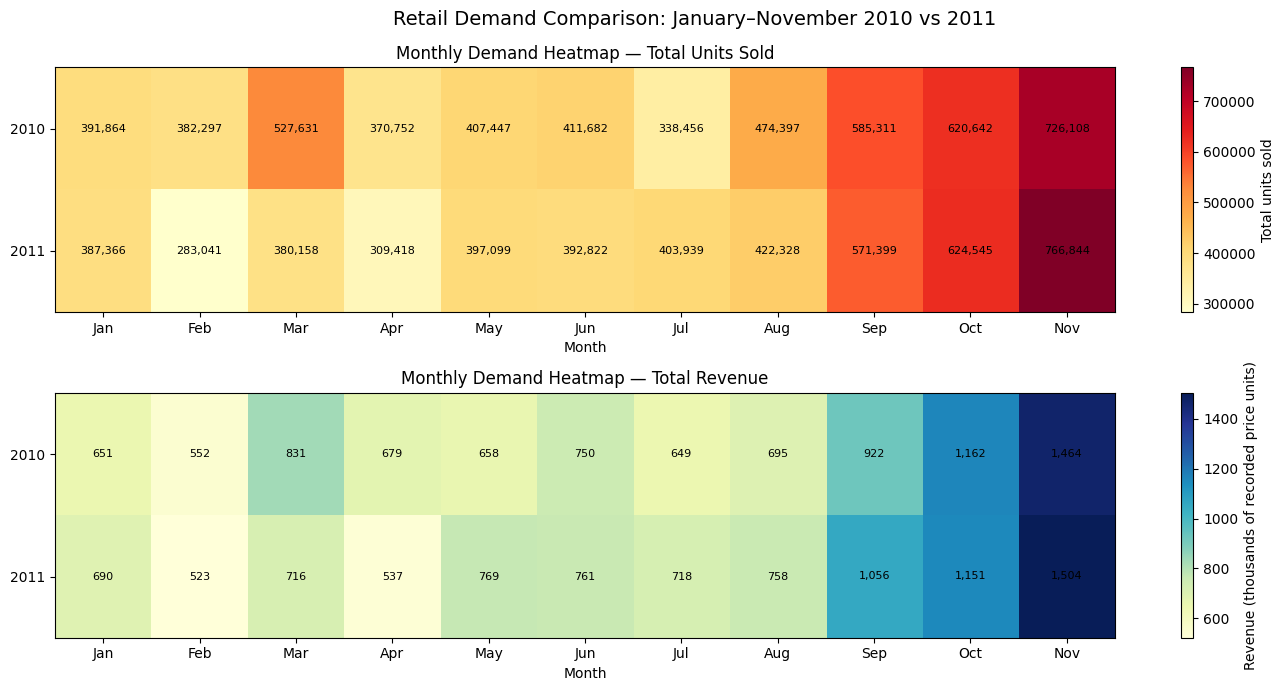

MONTHLY HEATMAP DATA


,Year,Month,Total_Units,Total_Revenue,Distinct_Invoices
0,2010,1,391864,651155.112,1106
1,2010,2,382297,551504.726,1203
2,2010,3,527631,830915.261,1687
3,2010,4,370752,678875.252,1464
4,2010,5,407447,657705.500,1504
5,2010,6,411682,749537.310,1652
6,2010,7,338456,648810.270,1534
7,2010,8,474397,695251.910,1427
8,2010,9,585311,921696.991,1845
9,2010,10,620642,1161902.220,2303


In [ ]:
# Q2: Monthly Demand Heatmaps — Quantity and Revenue

import pandas as pd
import matplotlib.pyplot as plt

# Prepare the comparable January-November period
heatmap_df = df_clean.copy()

heatmap_df["Year"] = heatmap_df["InvoiceDate"].dt.year
heatmap_df["Month"] = heatmap_df["InvoiceDate"].dt.month

heatmap_df = heatmap_df[
    heatmap_df["Year"].isin([2010, 2011]) &
    heatmap_df["Month"].between(1, 11)
].copy()

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov"
]

# Aggregate monthly quantity and revenue
monthly_heatmap = heatmap_df.pivot_table(
    index="Year",
    columns="Month",
    values=["Quantity", "Revenue"],
    aggfunc="sum",
    fill_value=0
)

units_table = monthly_heatmap["Quantity"].reindex(
    index=[2010, 2011], columns=range(1, 12), fill_value=0
)

revenue_table = monthly_heatmap["Revenue"].reindex(
    index=[2010, 2011], columns=range(1, 12), fill_value=0
)

# Create two heatmaps
fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# Heatmap A: Units sold
im1 = axes[0].imshow(
    units_table.values, aspect="auto", cmap="YlOrRd"
)
axes[0].set_title("Monthly Demand Heatmap — Total Units Sold")
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["2010", "2011"])
axes[0].set_xticks(range(11))
axes[0].set_xticklabels(month_labels)
axes[0].set_xlabel("Month")

for i in range(2):
    for j in range(11):
        axes[0].text(
            j, i, f"{units_table.iloc[i, j]:,.0f}",
            ha="center", va="center", fontsize=8
        )

fig.colorbar(im1, ax=axes[0], label="Total units sold")

# Heatmap B: Revenue
revenue_thousands = revenue_table / 1000

im2 = axes[1].imshow(
    revenue_thousands.values, aspect="auto", cmap="YlGnBu"
)
axes[1].set_title("Monthly Demand Heatmap — Total Revenue")
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["2010", "2011"])
axes[1].set_xticks(range(11))
axes[1].set_xticklabels(month_labels)
axes[1].set_xlabel("Month")

for i in range(2):
    for j in range(11):
        axes[1].text(
            j, i, f"{revenue_thousands.iloc[i, j]:,.0f}",
            ha="center", va="center", fontsize=8
        )

fig.colorbar(
    im2, ax=axes[1],
    label="Revenue (thousands of recorded price units)"
)

fig.suptitle(
    "Retail Demand Comparison: January–November 2010 vs 2011",
    fontsize=14
)
plt.tight_layout()
plt.show()

# Save the data used to create the heatmaps
monthly_heatmap_export = (
    heatmap_df.groupby(["Year", "Month"])
    .agg(
        Total_Units=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Distinct_Invoices=("Invoice", "nunique")
    )
    .reset_index()
)

print("MONTHLY HEATMAP DATA")
display(monthly_heatmap_export)

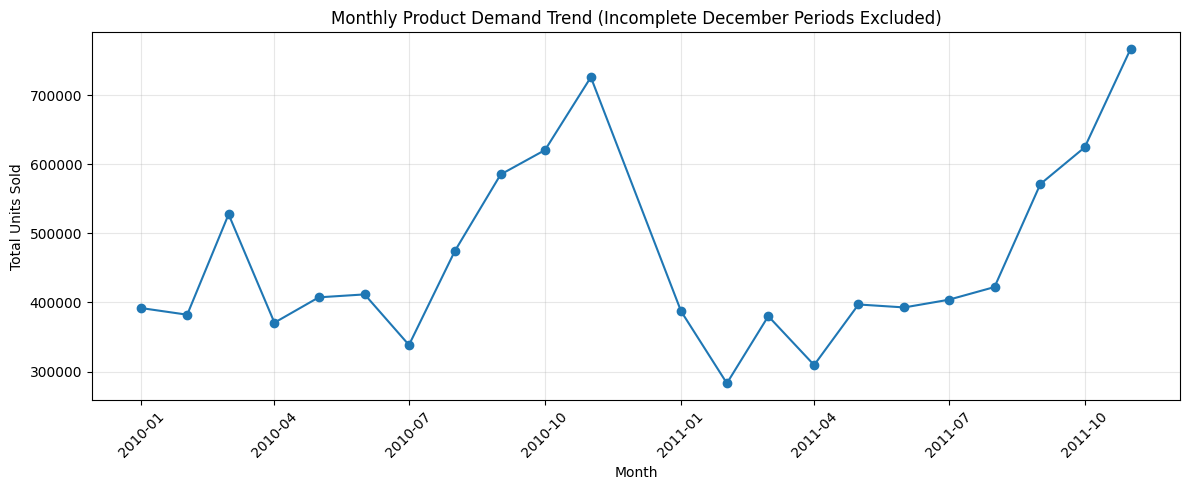

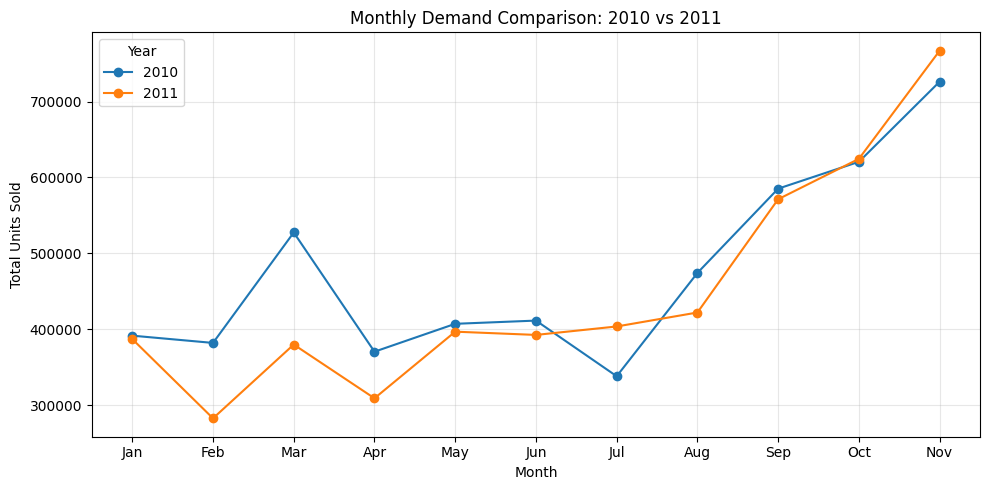

In [ ]:
import matplotlib.pyplot as plt

# December observations are partial in 2009, 2010 and 2011; exclude all Decembers.
complete_months = monthly.loc[monthly["Month"] != 12].copy()

complete_months["Month_Date"] = pd.to_datetime(
    complete_months["YearMonth"] + "-01"
)

# CHART 1: Overall monthly demand trend
plt.figure(figsize=(12, 5))
plt.plot(
    complete_months["Month_Date"],
    complete_months["Total_Units"],
    marker="o"
)
plt.title("Monthly Product Demand Trend (Incomplete December Periods Excluded)")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/content/monthly_product_demand_trend.png", dpi=200, bbox_inches="tight")
plt.show()

# CHART 2: Compare the same months in 2010 and 2011
comparison = monthly.loc[
    monthly["Year"].isin([2010, 2011]) &
    (monthly["Month"] <= 11)
]

month_comparison = comparison.pivot(
    index="Month",
    columns="Year",
    values="Total_Units"
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov"
]

plt.figure(figsize=(10, 5))
plt.plot(
    month_names,
    month_comparison.loc[1:11, 2010],
    marker="o",
    label="2010"
)
plt.plot(
    month_names,
    month_comparison.loc[1:11, 2011],
    marker="o",
    label="2011"
)
plt.title("Monthly Demand Comparison: 2010 vs 2011")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.legend(title="Year")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/monthly_demand_year_over_year.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Additional EDA: Investigating the March Demand Difference

This focused check inspects the products contributing the largest quantities in March 2010 and compares total March quantities with March 2011. It is exploratory and does not by itself establish why demand differed.

In [ ]:
# Investigate the March 2010 demand spike

march_2010 = df_clean[
    (df_clean["Year"] == 2010) &
    (df_clean["Month"] == 3)
]

march_products = (
    march_2010.groupby(["StockCode", "Description"])["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

print("TOP 15 PRODUCTS BY QUANTITY — MARCH 2010")
display(march_products)

print("\nTotal units in March 2010:", march_2010["Quantity"].sum())
print("Total units in March 2011:", df_clean.loc[
    (df_clean["Year"] == 2011) &
    (df_clean["Month"] == 3),
    "Quantity"
].sum())

TOP 15 PRODUCTS BY QUANTITY — MARCH 2010


,StockCode,Description,Quantity
0,21091,SET/6 WOODLAND PAPER PLATES,13119
1,21085,SET/6 WOODLAND PAPER CUPS,13071
2,21099,SET/6 STRAWBERRY PAPER CUPS,13009
3,21092,SET/6 STRAWBERRY PAPER PLATES,12506
4,21982,PACK OF 12 SUKI TISSUES,11806
5,21981,PACK OF 12 WOODLAND TISSUES,11576
6,21984,PACK OF 12 PINK PAISLEY TISSUES,11336
7,21980,PACK OF 12 RED SPOTTY TISSUES,10799
8,84568,GIRLS ALPHABET IRON ON PATCHES,5900
9,37351,ORANGE FLOWER MUG,5364



Total units in March 2010: 527631
Total units in March 2011: 380158


## Q3. Data Cleaning and Validation [CO3, BL4]

Question: Which data-quality issues could distort product-demand analysis, and how do the documented cleaning decisions affect the analysis-ready dataset?

The cleaning is performed earlier in the notebook so that all subsequent analyses use the same prepared data. The table below validates the row counts at each sequential step, compares missing values only for the original eight columns, and records zero-price rows retained. Negative and zero quantities are excluded from the primary positive-sales analysis; results therefore are not net sales after returns.

In [ ]:
# Q3: Data Cleaning Summary and Validation [CO3, BL4]

import pandas as pd

# Only compare the eight columns that existed in the original dataset.
original_columns = [
    "Invoice", "StockCode", "Description", "Quantity",
    "InvoiceDate", "Price", "Customer ID", "Country"
]

# Record row counts at each sequential cleaning stage.
steps = [
    ("Original dataset", 0),
    ("Exact duplicate removal", duplicates_removed),
    ("Cancelled invoice removal", cancelled_removed),
    ("Non-positive quantity removal", quantity_removed),
    ("Negative price removal", negative_prices_removed),
    ("Missing description removal", missing_descriptions_removed)
]

rows_before = original_rows
cleaning_records = []
for step_name, removed in steps:
    rows_after = rows_before - removed
    cleaning_records.append({
        "Cleaning Step": step_name,
        "Rows Before": rows_before,
        "Rows Removed": removed,
        "Rows After": rows_after
    })
    rows_before = rows_after

cleaning_summary = pd.DataFrame(cleaning_records)
print("DATA CLEANING SUMMARY — ROW COUNTS")
display(cleaning_summary)

missing_summary = pd.DataFrame({
    "Missing Before": df[original_columns].isna().sum(),
    "Missing After": df_clean[original_columns].isna().sum()
})
print("\nMISSING VALUES BEFORE AND AFTER CLEANING (ORIGINAL COLUMNS)")
display(missing_summary)

zero_prices_before = int((df["Price"] == 0).sum())
zero_prices_after = int((df_clean["Price"] == 0).sum())
print("\nZERO-PRICE AUDIT")
print("Zero-price rows before cleaning:", zero_prices_before)
print("Zero-price rows retained:", zero_prices_after)

expected_final_rows = original_rows - sum(removed for _, removed in steps)
print("\nFINAL VALIDATION")
print("Calculated final row count:", expected_final_rows)
print("Actual cleaned row count:", len(df_clean))
assert expected_final_rows == len(df_clean), "Cleaning counts do not reconcile."
assert len(df_clean) == 1_008_892, "Unexpected cleaned row count."
print("Validation passed: cleaning counts reconcile.")

DATA CLEANING SUMMARY — ROW COUNTS


,Cleaning Step,Rows Before,Rows Removed,Rows After
0,Original dataset,1067371,0,1067371
1,Exact duplicate removal,1067371,34335,1033036
2,Cancelled invoice removal,1033036,19104,1013932
3,Non-positive quantity removal,1013932,3393,1010539
4,Negative price removal,1010539,5,1010534
5,Missing description removal,1010534,1642,1008892



MISSING VALUES BEFORE AND AFTER CLEANING (ORIGINAL COLUMNS)


,Missing Before,Missing After
Invoice,0,0
StockCode,0,0
Description,4382,0
Quantity,0,0
InvoiceDate,0,0
Price,0,0
Customer ID,243007,229397
Country,0,0



ZERO-PRICE AUDIT
Zero-price rows before cleaning: 6202
Zero-price rows retained: 979

FINAL VALIDATION
Calculated final row count: 1008892
Actual cleaned row count: 1008892
Validation passed: cleaning counts reconcile.


## Q4. Product-Level Recurring Peaks [CO4, BL4]

Question: Which individual products show the same peak month in both comparison years, and how strong is the evidence?

Candidate screening rules:
1. At least 10 distinct invoices in each year.
2. Same peak month in both years.
3. Peak-to-average monthly quantity ratio of at least 1.5 in each year.
4. At least 10 distinct invoices in the peak month in both years.

Monthly-profile correlation is supporting evidence only. These rules are exploratory, and the resulting list should be described as recurring-peak candidates, not definitive long-term seasonality.

In [ ]:
import numpy as np
import pandas as pd

# Q4: Product-level recurring peak analysis [CO4, BL4]
# Primary analysis: January-November 2010 vs January-November 2011
primary_data = work[
    work["Year"].isin([2010, 2011]) &
    work["Month"].between(1, 11)
].copy()

print("Analysis period: January-November 2010 vs January-November 2011")
print("Rows:", len(primary_data))

# Aggregate units and distinct invoices by product, year, and month
product_month_primary = primary_data.groupby(
    ["ProductKey", "Year", "Month"]
).agg(
    Units=("Quantity", "sum"),
    Orders=("Invoice", "nunique")
).reset_index()

# Select the most frequently observed description for each product
labels_data = primary_data.assign(
    Description_Label=primary_data["Description"]
    .astype("string").str.strip()
)

product_names_primary = (
    labels_data.groupby(["ProductKey", "Description_Label"])
    .size()
    .rename("Frequency")
    .reset_index()
    .sort_values("Frequency", ascending=False)
    .drop_duplicates("ProductKey")
    .set_index("ProductKey")["Description_Label"]
)

# Ensure every product has columns for all 11 months in both years
expected = pd.MultiIndex.from_product(
    [[2010, 2011], range(1, 12)],
    names=["Year", "Month"]
)

units_primary = product_month_primary.pivot(
    index="ProductKey",
    columns=["Year", "Month"],
    values="Units"
).reindex(columns=expected).fillna(0)

orders_primary = product_month_primary.pivot(
    index="ProductKey",
    columns=["Year", "Month"],
    values="Orders"
).reindex(
    index=units_primary.index,
    columns=expected
).fillna(0)

u10_primary = units_primary.xs(2010, axis=1, level="Year")
u11_primary = units_primary.xs(2011, axis=1, level="Year")
o10_primary = orders_primary.xs(2010, axis=1, level="Year")
o11_primary = orders_primary.xs(2011, axis=1, level="Year")

# Peak month and peak-to-average ratio for each year
peak10_primary = u10_primary.idxmax(axis=1)
peak11_primary = u11_primary.idxmax(axis=1)

index10_primary = (
    u10_primary.max(axis=1) /
    u10_primary.mean(axis=1).replace(0, np.nan)
)

index11_primary = (
    u11_primary.max(axis=1) /
    u11_primary.mean(axis=1).replace(0, np.nan)
)

def peak_invoice_counts(monthly_orders, peak_months):
    values = monthly_orders.to_numpy()[
        np.arange(len(monthly_orders)),
        peak_months.to_numpy() - 1
    ]
    return pd.Series(values, index=monthly_orders.index)

# Compare the full 11-month demand profiles
correlations = {}

for key in units_primary.index:
    x = u10_primary.loc[key].to_numpy(dtype=float)
    y = u11_primary.loc[key].to_numpy(dtype=float)

    if np.std(x) > 0 and np.std(y) > 0:
        correlations[key] = np.corrcoef(x, y)[0, 1]
    else:
        correlations[key] = np.nan

profile_primary = pd.DataFrame(index=units_primary.index)
profile_primary["Description"] = product_names_primary.reindex(
    profile_primary.index
)
profile_primary["Peak_Month_2010"] = peak10_primary
profile_primary["Peak_Month_2011"] = peak11_primary
profile_primary["Peak_Index_2010"] = index10_primary.round(2)
profile_primary["Peak_Index_2011"] = index11_primary.round(2)
profile_primary["Invoices_2010"] = o10_primary.sum(axis=1).astype(int)
profile_primary["Invoices_2011"] = o11_primary.sum(axis=1).astype(int)

profile_primary["Peak_Invoices_2010"] = (
    peak_invoice_counts(o10_primary, peak10_primary).astype(int)
)
profile_primary["Peak_Invoices_2011"] = (
    peak_invoice_counts(o11_primary, peak11_primary).astype(int)
)

profile_primary["Profile_Correlation"] = pd.Series(correlations)
profile_primary["Same_Peak_Month"] = (
    profile_primary["Peak_Month_2010"] ==
    profile_primary["Peak_Month_2011"]
)
profile_primary["Repeat_Strength"] = profile_primary[
    ["Peak_Index_2010", "Peak_Index_2011"]
].min(axis=1)

month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
    9: "Sep", 10: "Oct", 11: "Nov"
}
profile_primary["Peak_Month_Name"] = (
    profile_primary["Peak_Month_2010"].map(month_names)
)

# Screening rules: evidence of activity and recurring peaks
eligible_primary = profile_primary[
    (profile_primary["Invoices_2010"] >= 10) &
    (profile_primary["Invoices_2011"] >= 10)
].copy()

repeated_primary = eligible_primary[
    eligible_primary["Same_Peak_Month"] &
    (eligible_primary["Peak_Index_2010"] >= 1.5) &
    (eligible_primary["Peak_Index_2011"] >= 1.5)
].copy()

watchlist_primary = repeated_primary[
    (repeated_primary["Peak_Invoices_2010"] >= 10) &
    (repeated_primary["Peak_Invoices_2011"] >= 10)
].copy()

watchlist_primary = watchlist_primary.sort_values(
    ["Profile_Correlation", "Repeat_Strength"],
    ascending=False,
    na_position="last"
)

print("\nPRIMARY ANALYSIS COUNTS")
print("Eligible products:", len(eligible_primary))
print("Products with recurring peak months:", len(repeated_primary))
print("Candidates with at least 10 peak-month invoices in both years:",
      len(watchlist_primary))

print("\nTOP 20 CANDIDATES")
display(watchlist_primary[[
    "Description",
    "Peak_Month_Name",
    "Peak_Index_2010",
    "Peak_Index_2011",
    "Peak_Invoices_2010",
    "Peak_Invoices_2011",
    "Profile_Correlation"
]].head(20))

print("\nPEAK-MONTH DISTRIBUTION")
distribution_primary = (
    watchlist_primary["Peak_Month_Name"]
    .value_counts()
    .reindex(
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
         "Jul", "Aug", "Sep", "Oct", "Nov"],
        fill_value=0
    )
)
print(distribution_primary.to_string())

Analysis period: January-November 2010 vs January-November 2011
Rows: 899453

PRIMARY ANALYSIS COUNTS
Eligible products: 2358
Products with recurring peak months: 426
Candidates with at least 10 peak-month invoices in both years: 292

TOP 20 CANDIDATES


,Description,Peak_Month_Name,Peak_Index_2010,Peak_Index_2011,Peak_Invoices_2010,Peak_Invoices_2011,Profile_Correlation
ProductKey,,,,,,,
22086,PAPER CHAIN KIT 50'S CHRISTMAS,Nov,6.42,5.88,329,390,0.995196
21355,TOAST ITS - I LOVE YOU,Jan,5.91,7.85,52,55,0.990242
22130,PARTY CONE CHRISTMAS DECORATION,Nov,5.69,5.58,96,18,0.989865
84459A,PINK METAL CHICKEN HEART,Mar,4.63,6.25,31,20,0.987389
22731,3D CHRISTMAS STAMPS STICKERS,Oct,5.06,4.55,44,46,0.987211
22734,SET OF 6 RIBBONS VINTAGE CHRISTMAS,Nov,4.85,4.43,118,149,0.986394
22818,CARD CHRISTMAS VILLAGE,Nov,5.08,4.96,72,79,0.982081
22816,CARD MOTORBIKE SANTA,Nov,4.64,5.31,76,88,0.980932
22158,3 HEARTS HANGING DECORATION RUSTIC,Nov,5.27,5.09,147,100,0.979520



PEAK-MONTH DISTRIBUTION
Peak_Month_Name
Jan     27
Feb      3
Mar     28
Apr      7
May     17
Jun      7
Jul      3
Aug      4
Sep      7
Oct     33
Nov    156


### Q4 Interpretation

The primary analysis reports the eligible-product count, the number with repeated peak months, and the final candidate count after peak-month invoice support. The main result from the current analysis is 2,358 eligible products and 292 recurring-peak candidates; November is the most frequent peak month, with 156 candidates.

### Representative Product Validation

Three representative products with recurring peaks in March, October and November are compared using monthly units and distinct invoice activity across January–November 2010 and 2011. The full candidate watchlist remains unchanged.


REPRESENTATIVE PRODUCTS — DIFFERENT PEAK MONTHS


,ProductKey,Description,Repeated_Peak_Month,Peak_Index_2010,Peak_Index_2011,Peak_Invoices_2010,Peak_Invoices_2011,Profile_Correlation
0,84459A,PINK METAL CHICKEN HEART,Mar,4.63,6.25,31,20,0.987389
1,22731,3D CHRISTMAS STAMPS STICKERS,Oct,5.06,4.55,44,46,0.987211
2,22086,PAPER CHAIN KIT 50'S CHRISTMAS,Nov,6.42,5.88,329,390,0.995196


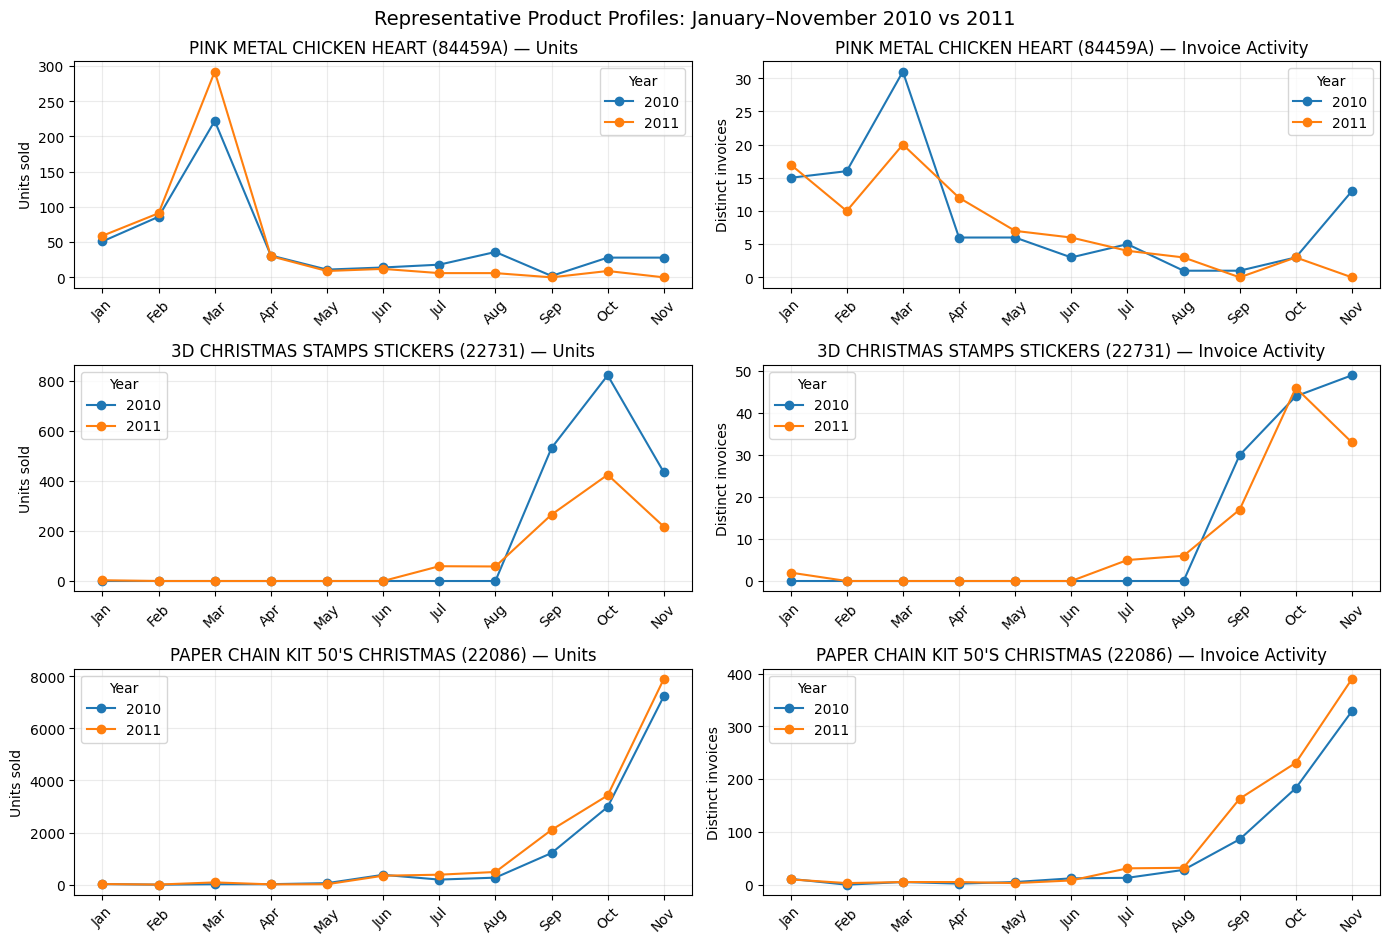

Monthly quantity and invoice data prepared: 66 rows


,ProductKey,Description,Year,Month,Month_Name,Units,Distinct_Invoices
0,84459A,PINK METAL CHICKEN HEART,2010,1,Jan,51,15
1,84459A,PINK METAL CHICKEN HEART,2010,2,Feb,86,16
2,84459A,PINK METAL CHICKEN HEART,2010,3,Mar,222,31
3,84459A,PINK METAL CHICKEN HEART,2010,4,Apr,31,6
4,84459A,PINK METAL CHICKEN HEART,2010,5,May,11,6
5,84459A,PINK METAL CHICKEN HEART,2010,6,Jun,14,3
6,84459A,PINK METAL CHICKEN HEART,2010,7,Jul,18,5
7,84459A,PINK METAL CHICKEN HEART,2010,8,Aug,36,1
8,84459A,PINK METAL CHICKEN HEART,2010,9,Sep,2,1
9,84459A,PINK METAL CHICKEN HEART,2010,10,Oct,28,3


In [ ]:
# Q4: Validate Representative Products Across Both Years [CO4, BL4]

import matplotlib.pyplot as plt
import pandas as pd

# Choose high-ranked examples with different repeated peak months.
month_name_map = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov"
}

representative_rows = []
for peak_month in [3, 10, 11]:
    options = watchlist_primary[
        watchlist_primary["Peak_Month_2010"] == peak_month
    ].sort_values(
        ["Profile_Correlation", "Repeat_Strength"],
        ascending=False,
        na_position="last"
    )
    if options.empty:
        continue
    product_key = options.index[0]
    row = options.loc[product_key]
    representative_rows.append({
        "ProductKey": product_key,
        "Description": row["Description"],
        "Repeated_Peak_Month": month_name_map[peak_month],
        "Peak_Index_2010": row["Peak_Index_2010"],
        "Peak_Index_2011": row["Peak_Index_2011"],
        "Peak_Invoices_2010": int(row["Peak_Invoices_2010"]),
        "Peak_Invoices_2011": int(row["Peak_Invoices_2011"]),
        "Profile_Correlation": row["Profile_Correlation"]
    })

selected_product_summary = pd.DataFrame(representative_rows)
print("REPRESENTATIVE PRODUCTS — DIFFERENT PEAK MONTHS")
display(selected_product_summary)

monthly_records = []
fig, axes = plt.subplots(
    len(selected_product_summary), 2,
    figsize=(14, max(8, 3.2 * len(selected_product_summary))),
    squeeze=False
)
month_nums = list(range(1, 12))
month_labels = [month_name_map[m] for m in month_nums]

for row_idx, product in selected_product_summary.iterrows():
    product_key = product["ProductKey"]
    description = product["Description"]

    for year in [2010, 2011]:
        product_rows = work[
            (work["ProductKey"] == product_key) &
            (work["Year"] == year) &
            (work["Month"].between(1, 11))
        ]
        by_month = product_rows.groupby("Month").agg(
            Units=("Quantity", "sum"),
            Distinct_Invoices=("Invoice", "nunique")
        ).reindex(month_nums, fill_value=0)

        axes[row_idx, 0].plot(
            month_nums, by_month["Units"], marker="o", label=str(year)
        )
        axes[row_idx, 1].plot(
            month_nums, by_month["Distinct_Invoices"], marker="o", label=str(year)
        )

        for month_num in month_nums:
            monthly_records.append({
                "ProductKey": product_key,
                "Description": description,
                "Year": year,
                "Month": month_num,
                "Month_Name": month_name_map[month_num],
                "Units": int(by_month.loc[month_num, "Units"]),
                "Distinct_Invoices": int(by_month.loc[month_num, "Distinct_Invoices"])
            })

    axes[row_idx, 0].set_title(f"{description} ({product_key}) — Units")
    axes[row_idx, 1].set_title(f"{description} ({product_key}) — Invoice Activity")
    for col in range(2):
        axes[row_idx, col].set_xticks(month_nums)
        axes[row_idx, col].set_xticklabels(month_labels, rotation=45)
        axes[row_idx, col].grid(True, alpha=0.25)
        axes[row_idx, col].legend(title="Year")
    axes[row_idx, 0].set_ylabel("Units sold")
    axes[row_idx, 1].set_ylabel("Distinct invoices")

plt.suptitle(
    "Representative Product Profiles: January–November 2010 vs 2011",
    fontsize=14
)
plt.tight_layout()
plt.savefig(
    "/content/selected_product_monthly_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

selected_product_monthly = pd.DataFrame(monthly_records)
print("Monthly quantity and invoice data prepared:", len(selected_product_monthly), "rows")
display(selected_product_monthly.head(12))

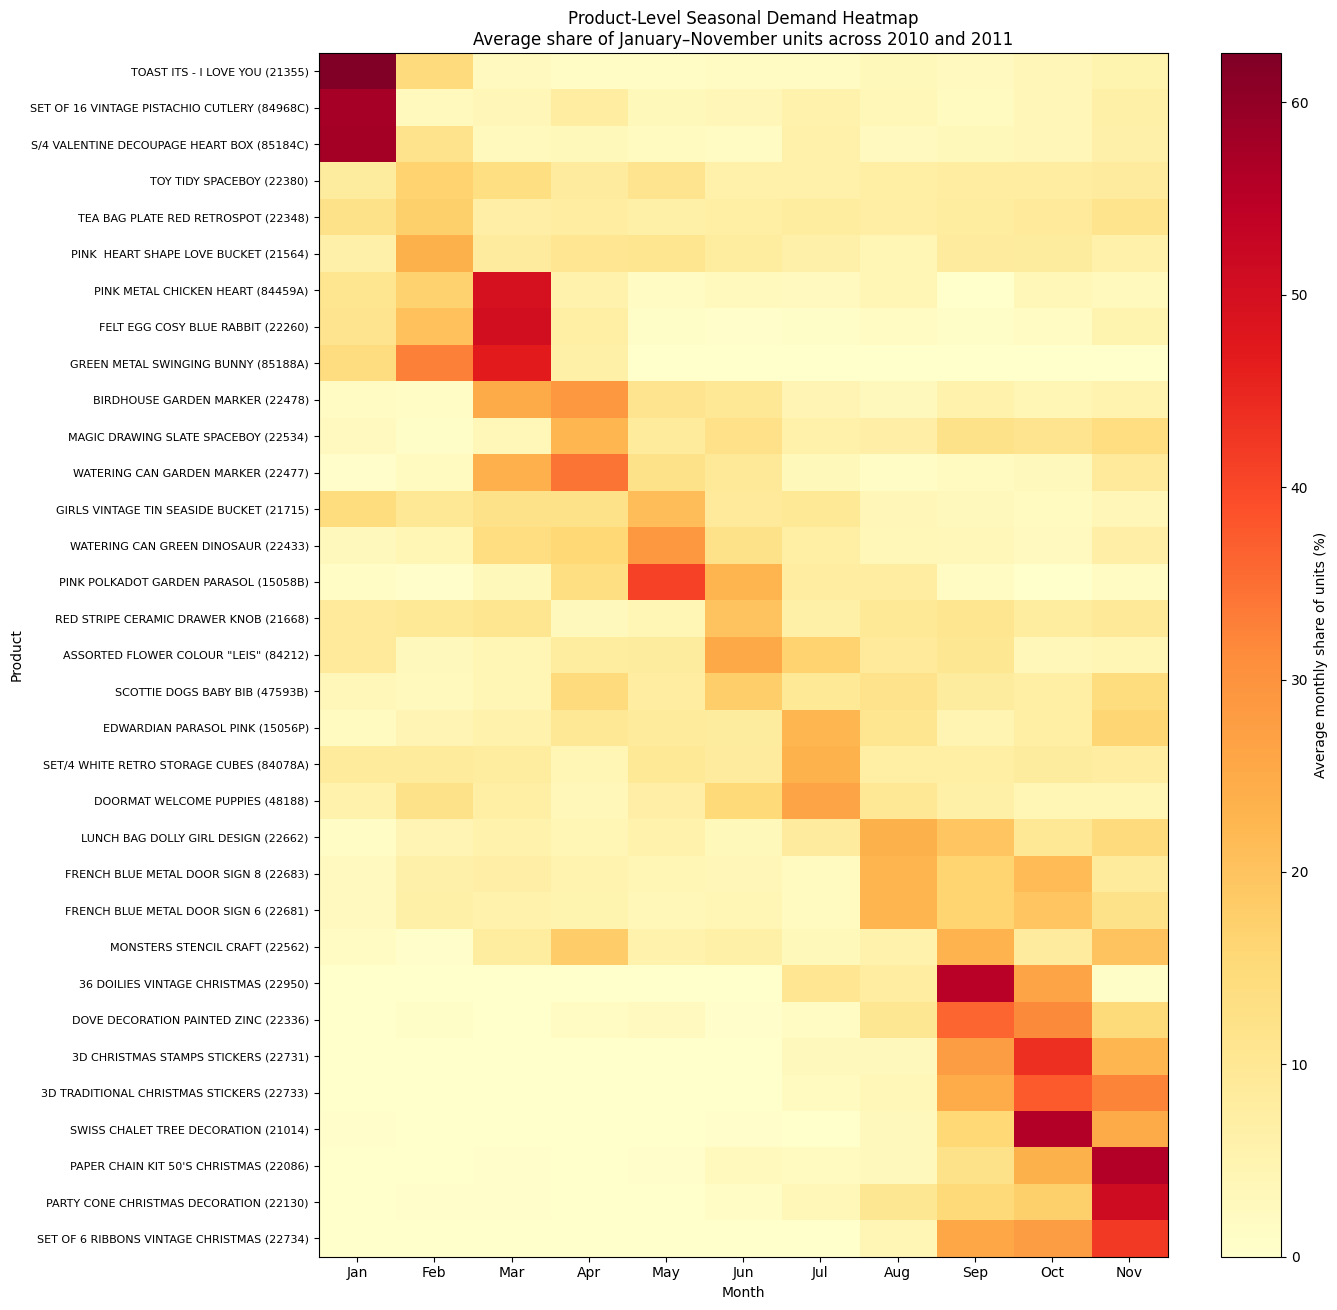

Candidates in the displayed heatmap: 33
Rows in the full exported matrix: 292
Files saved:
- /content/product_seasonality_heatmap.png
- /content/full_product_month_share_matrix.csv


In [ ]:
# Q4: Product-Level Seasonal Demand Heatmap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select up to three strong candidates for each peak month
ranked_candidates = watchlist_primary.sort_values(
    ["Profile_Correlation", "Repeat_Strength"],
    ascending=False,
    na_position="last"
)

selected_products = (
    ranked_candidates
    .groupby("Peak_Month_2010", sort=True)
    .head(3)
    .sort_values(
        ["Peak_Month_2010", "Profile_Correlation"],
        ascending=[True, False]
    )
)

# Calculate each product's percentage of annual-window units by month
share_2010 = u10_primary.div(
    u10_primary.sum(axis=1).replace(0, np.nan),
    axis=0
) * 100

share_2011 = u11_primary.div(
    u11_primary.sum(axis=1).replace(0, np.nan),
    axis=0
) * 100

# Average the monthly shares across the two years
heatmap_matrix = (
    share_2010.loc[selected_products.index]
    + share_2011.loc[selected_products.index]
) / 2

# Readable product labels
product_labels = [
    f"{watchlist_primary.loc[key, 'Description']} ({key})"
    for key in heatmap_matrix.index
]

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov"
]

# Draw the visualization
fig, ax = plt.subplots(
    figsize=(14, max(7, len(heatmap_matrix) * 0.4))
)

image = ax.imshow(
    heatmap_matrix.to_numpy(),
    aspect="auto",
    cmap="YlOrRd",
    interpolation="nearest"
)

ax.set_xticks(range(11))
ax.set_xticklabels(month_labels)
ax.set_yticks(range(len(product_labels)))
ax.set_yticklabels(product_labels, fontsize=8)

ax.set_xlabel("Month")
ax.set_ylabel("Product")
ax.set_title(
    "Product-Level Seasonal Demand Heatmap\n"
    "Average share of January–November units across 2010 and 2011"
)

fig.colorbar(
    image,
    ax=ax,
    label="Average monthly share of units (%)"
)

plt.tight_layout()
plt.savefig(
    "/content/product_seasonality_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Export the full monthly-share matrix for all 292 candidates
full_share_matrix = (
    share_2010.loc[watchlist_primary.index]
    + share_2011.loc[watchlist_primary.index]
) / 2

full_share_matrix.insert(
    0,
    "Description",
    watchlist_primary["Description"]
)

full_share_matrix.to_csv(
    "/content/full_product_month_share_matrix.csv",
    index_label="ProductKey"
)

print("Candidates in the displayed heatmap:", len(heatmap_matrix))
print("Rows in the full exported matrix:", len(full_share_matrix))
print("Files saved:")
print("- /content/product_seasonality_heatmap.png")
print("- /content/full_product_month_share_matrix.csv")

## Q5. Visualization, Sensitivity Analysis and Inventory Recommendations [CO5, BL5]

Question: What recurring patterns are visible, how sensitive is the candidate list to the screening rules, and what inventory-planning recommendations are reasonably supported by the data?

The next cells rank the candidates, visualize the peak-month distribution, and test alternative peak-strength and invoice-support thresholds. Thresholds are exploratory choices, not statistically validated cutoffs.

RECURRING-PEAK CANDIDATES BY MONTH
Peak_Month_Name
Jan     27
Feb      3
Mar     28
Apr      7
May     17
Jun      7
Jul      3
Aug      4
Sep      7
Oct     33
Nov    156

Total candidates: 292


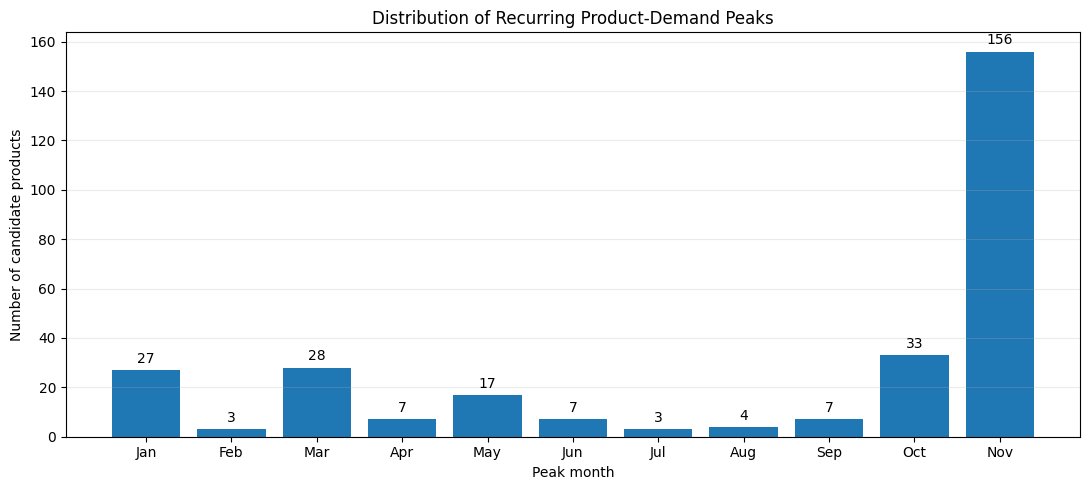


TOP 20 RECURRING-PEAK CANDIDATES


,Description,Peak_Month_Name,Peak_Index_2010,Peak_Index_2011,Peak_Invoices_2010,Peak_Invoices_2011,Profile_Correlation
ProductKey,,,,,,,
22086,PAPER CHAIN KIT 50'S CHRISTMAS,Nov,6.42,5.88,329,390,0.995196
21355,TOAST ITS - I LOVE YOU,Jan,5.91,7.85,52,55,0.990242
22130,PARTY CONE CHRISTMAS DECORATION,Nov,5.69,5.58,96,18,0.989865
84459A,PINK METAL CHICKEN HEART,Mar,4.63,6.25,31,20,0.987389
22731,3D CHRISTMAS STAMPS STICKERS,Oct,5.06,4.55,44,46,0.987211
22734,SET OF 6 RIBBONS VINTAGE CHRISTMAS,Nov,4.85,4.43,118,149,0.986394
22818,CARD CHRISTMAS VILLAGE,Nov,5.08,4.96,72,79,0.982081
22816,CARD MOTORBIKE SANTA,Nov,4.64,5.31,76,88,0.980932
22158,3 HEARTS HANGING DECORATION RUSTIC,Nov,5.27,5.09,147,100,0.979520



Bar chart saved to /content/peak_month_distribution.png


In [ ]:
# Q5: Peak-Month Distribution and Top 20 Candidates

import matplotlib.pyplot as plt
import pandas as pd

month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov"
]

# Count candidates by their recurring peak month
peak_counts = (
    watchlist_primary["Peak_Month_Name"]
    .value_counts()
    .reindex(month_order, fill_value=0)
)

print("RECURRING-PEAK CANDIDATES BY MONTH")
print(peak_counts.to_string())
print("\nTotal candidates:", int(peak_counts.sum()))

assert int(peak_counts.sum()) == len(watchlist_primary), \
    "Peak-month counts do not match the watchlist!"

# Create bar chart
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    peak_counts.index,
    peak_counts.values
)

ax.bar_label(bars, padding=3)
ax.set_title("Distribution of Recurring Product-Demand Peaks")
ax.set_xlabel("Peak month")
ax.set_ylabel("Number of candidate products")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    "/content/peak_month_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Prepare the top 20 candidates
top20_primary = watchlist_primary.sort_values(
    ["Profile_Correlation", "Repeat_Strength"],
    ascending=False,
    na_position="last"
).head(20)

top20_table = top20_primary[[
    "Description",
    "Peak_Month_Name",
    "Peak_Index_2010",
    "Peak_Index_2011",
    "Peak_Invoices_2010",
    "Peak_Invoices_2011",
    "Profile_Correlation"
]].copy()

top20_table.index.name = "ProductKey"

print("\nTOP 20 RECURRING-PEAK CANDIDATES")
display(top20_table)

print("\nBar chart saved to /content/peak_month_distribution.png")

In [ ]:
# Q5: Sensitivity Analysis of Product Screening Rules

import pandas as pd

# Test different peak-to-average thresholds
peak_thresholds = [1.25, 1.5, 2.0]
results = []

for threshold in peak_thresholds:

    # Rule 1: Same peak month and sufficient peak strength
    base_candidates = eligible_primary[
        eligible_primary["Same_Peak_Month"] &
        (eligible_primary["Peak_Index_2010"] >= threshold) &
        (eligible_primary["Peak_Index_2011"] >= threshold)
    ].copy()

    # Rule 2: Also require >= 10 distinct invoices at each peak
    supported_candidates = base_candidates[
        (base_candidates["Peak_Invoices_2010"] >= 10) &
        (base_candidates["Peak_Invoices_2011"] >= 10)
    ]

    results.append({
        "Peak Index Threshold": threshold,
        "Same-Peak Candidates": len(base_candidates),
        "Candidates With Peak Invoice Support": len(supported_candidates)
    })

sensitivity_results = pd.DataFrame(results)

print("SENSITIVITY TO PEAK-STRENGTH THRESHOLD")
display(sensitivity_results)

# Separately test the minimum invoice requirement,
# keeping the peak-index threshold fixed at 1.5
invoice_results = []

base = eligible_primary[
    eligible_primary["Same_Peak_Month"] &
    (eligible_primary["Peak_Index_2010"] >= 1.5) &
    (eligible_primary["Peak_Index_2011"] >= 1.5)
].copy()

for minimum_invoices in [0, 10, 20]:

    if minimum_invoices == 0:
        selected = base
    else:
        selected = base[
            (base["Peak_Invoices_2010"] >= minimum_invoices) &
            (base["Peak_Invoices_2011"] >= minimum_invoices)
        ]

    invoice_results.append({
        "Minimum Invoices At Peak (each year)": minimum_invoices,
        "Candidate Count": len(selected)
    })

invoice_sensitivity = pd.DataFrame(invoice_results)

print("\nSENSITIVITY TO PEAK-MONTH INVOICE REQUIREMENT")
display(invoice_sensitivity)

SENSITIVITY TO PEAK-STRENGTH THRESHOLD


,Peak Index Threshold,Same-Peak Candidates,Candidates With Peak Invoice Support
0,1.25,435,301
1,1.50,426,292
2,2.00,348,224



SENSITIVITY TO PEAK-MONTH INVOICE REQUIREMENT


,Minimum Invoices At Peak (each year),Candidate Count
0,0,426
1,10,292
2,20,215


### Interpretation and Limitations

In the current primary analysis, 292 products meet the screening rules, and 156 have a November peak (53.4% of the candidate list). October has 33 candidates and March has 28. These counts describe the screened candidate list, not the proportion of all retail products that are seasonal.

The dataset covers only two comparable annual windows. Invoice counts measure transaction activity, not unique customers. The analysis retains zero-price records, excludes non-positive quantities and cancellation-coded invoices, and therefore describes retained positive-quantity transactions rather than net sales after returns. Similar descriptions are used to consolidate stock-code case variants only under a documented rule; descriptions alone do not guarantee true product identity.

In [ ]:

# ============================================================
# FINAL STEP: VALIDATE AND EXPORT THE EDAV PROJECT
# Run this cell after all analysis and chart-generation cells.
# ============================================================

import os
import shutil
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# ------------------------------------------------------------
# 0. OUTPUT DIRECTORY
# ------------------------------------------------------------

output_dir = "/content/EDAV_Final_Outputs"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 1. CHECK REQUIRED VARIABLES AND COLUMNS
# ------------------------------------------------------------

required_variables = [
    "watchlist_primary",
    "primary_data",
    "cleaning_summary",
    "df",
    "df_clean",
    "u10_primary",
    "u11_primary",
    "sensitivity_results",
    "invoice_sensitivity",
    "selected_product_summary",
    "selected_product_monthly",
    "eligible_primary",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise NameError(
        "Run the preceding analysis cells first. Missing variables: "
        + ", ".join(missing_variables)
    )

watchlist_columns = [
    "Peak_Month_2010",
    "Peak_Month_2011",
    "Peak_Index_2010",
    "Peak_Index_2011",
    "Peak_Invoices_2010",
    "Peak_Invoices_2011",
    "Invoices_2010",
    "Invoices_2011",
    "Peak_Month_Name",
    "Description",
]

missing_watchlist_columns = [
    col for col in watchlist_columns
    if col not in watchlist_primary.columns
]

if missing_watchlist_columns:
    raise KeyError(
        "Missing watchlist columns: "
        + ", ".join(missing_watchlist_columns)
    )

required_primary_columns = [
    "Year", "Month", "Quantity", "Revenue", "Invoice"
]

missing_primary_columns = [
    col for col in required_primary_columns
    if col not in primary_data.columns
]

if missing_primary_columns:
    raise KeyError(
        "Missing primary_data columns: "
        + ", ".join(missing_primary_columns)
    )

original_columns = [
    "Invoice", "StockCode", "Description", "Quantity",
    "InvoiceDate", "Price", "Customer ID", "Country"
]

for dataframe_name, dataframe in [
    ("df", df),
    ("df_clean", df_clean),
]:
    missing = [
        col for col in original_columns
        if col not in dataframe.columns
    ]
    if missing:
        raise KeyError(
            f"{dataframe_name} is missing columns: {missing}"
        )

# ------------------------------------------------------------
# 2. VALIDATE THE FINAL PRODUCT WATCHLIST
# ------------------------------------------------------------

final_watchlist = watchlist_primary.copy()

assert len(final_watchlist) == 292, (
    f"Expected 292 candidates, found {len(final_watchlist)}. "
    "Review the primary analysis."
)

assert (
    final_watchlist["Peak_Month_2010"]
    == final_watchlist["Peak_Month_2011"]
).all(), "Some candidates do not repeat their peak month."

assert (final_watchlist["Peak_Index_2010"] >= 1.5).all(), (
    "Some 2010 peak indices are below 1.5."
)

assert (final_watchlist["Peak_Index_2011"] >= 1.5).all(), (
    "Some 2011 peak indices are below 1.5."
)

assert (final_watchlist["Peak_Invoices_2010"] >= 10).all(), (
    "Some 2010 peak months have fewer than 10 invoices."
)

assert (final_watchlist["Peak_Invoices_2011"] >= 10).all(), (
    "Some 2011 peak months have fewer than 10 invoices."
)

assert (final_watchlist["Invoices_2010"] >= 10).all()
assert (final_watchlist["Invoices_2011"] >= 10).all()

print("Candidate validation passed:", len(final_watchlist))

# Validate the comparison window
assert set(primary_data["Year"].unique()) == {2010, 2011}, (
    "primary_data must contain only 2010 and 2011."
)

assert primary_data["Month"].between(1, 11).all(), (
    "primary_data contains months outside January-November."
)

print("Comparison window validated: January-November 2010 vs 2011.")

# ------------------------------------------------------------
# 3. EXPORT THE CLEANING SUMMARY AND MISSING-VALUE AUDIT
# ------------------------------------------------------------

cleaning_summary.to_csv(
    f"{output_dir}/data_cleaning_summary.csv",
    index=False
)

missing_audit = pd.DataFrame({
    "Missing_Before": df[original_columns].isna().sum(),
    "Missing_After": df_clean[original_columns].isna().sum()
})

missing_audit.to_csv(
    f"{output_dir}/missing_values_audit.csv",
    index=True,
    index_label="Column"
)

# ------------------------------------------------------------
# 4. EXPORT THE FINAL WATCHLIST AND TOP 20
# ------------------------------------------------------------

final_watchlist.to_csv(
    f"{output_dir}/final_seasonal_product_watchlist.csv",
    index_label="ProductKey"
)

top20 = final_watchlist.head(20)

top20.to_csv(
    f"{output_dir}/top_20_seasonal_products.csv",
    index_label="ProductKey"
)

# ------------------------------------------------------------
# 5. EXPORT MONTHLY QUANTITY, REVENUE AND INVOICE SUMMARY
# ------------------------------------------------------------

monthly_final = (
    primary_data.groupby(["Year", "Month"])
    .agg(
        Total_Units=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Distinct_Invoices=("Invoice", "nunique")
    )
    .reset_index()
    .sort_values(["Year", "Month"])
)

monthly_final.to_csv(
    f"{output_dir}/primary_monthly_demand_summary.csv",
    index=False
)

# Peak-month distribution
month_order = [
    "Jan", "Feb", "Mar", "Apr", "May",
    "Jun", "Jul", "Aug", "Sep", "Oct", "Nov"
]

peak_distribution = (
    final_watchlist["Peak_Month_Name"]
    .value_counts()
    .reindex(month_order, fill_value=0)
    .rename_axis("Peak_Month")
    .reset_index(name="Candidate_Count")
)

assert peak_distribution["Candidate_Count"].sum() == 292, (
    "Peak-month distribution does not total 292."
)

november_count = int(
    peak_distribution.loc[
        peak_distribution["Peak_Month"] == "Nov",
        "Candidate_Count"
    ].iloc[0]
)

assert november_count == 156, (
    f"Expected 156 November peaks, found {november_count}. "
    "Verify the analysis results."
)

peak_distribution.to_csv(
    f"{output_dir}/peak_month_distribution.csv",
    index=False
)

# Peak-month bar chart
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    peak_distribution["Peak_Month"],
    peak_distribution["Candidate_Count"]
)

ax.bar_label(bars, padding=3)
ax.set_title("Recurring Product-Demand Candidates by Peak Month")
ax.set_xlabel("Peak Month")
ax.set_ylabel("Number of Candidates")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
fig.savefig(
    f"{output_dir}/peak_month_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.close(fig)

# ------------------------------------------------------------
# 6. SAVE THE QUANTITY AND REVENUE HEATMAPS
# ------------------------------------------------------------

units = (
    monthly_final.pivot(
        index="Year",
        columns="Month",
        values="Total_Units"
    )
    .reindex(index=[2010, 2011], columns=range(1, 12))
)

revenue = (
    monthly_final.pivot(
        index="Year",
        columns="Month",
        values="Total_Revenue"
    )
    .reindex(index=[2010, 2011], columns=range(1, 12))
)

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

heatmap_tables = [
    (
        axes[0],
        units,
        "Monthly Total Units Sold",
        "YlOrRd"
    ),
    (
        axes[1],
        revenue / 1000,
        "Monthly Total Revenue (thousands)",
        "YlGnBu"
    ),
]

for ax, table, title, color_map in heatmap_tables:
    image = ax.imshow(
        table.to_numpy(dtype=float),
        aspect="auto",
        cmap=color_map
    )

    ax.set_title(title)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["2010", "2011"])
    ax.set_xticks(range(11))
    ax.set_xticklabels(month_order)
    ax.set_xlabel("Month")

    for i in range(2):
        for j in range(11):
            value = table.iloc[i, j]

            label = (
                "N/A" if pd.isna(value)
                else f"{value:,.0f}"
            )

            ax.text(
                j, i, label,
                ha="center",
                va="center",
                fontsize=8
            )

    fig.colorbar(image, ax=ax)

fig.suptitle(
    "Retail Demand Comparison: January-November 2010 vs 2011"
)
plt.tight_layout()

fig.savefig(
    f"{output_dir}/monthly_quantity_revenue_heatmaps.png",
    dpi=200,
    bbox_inches="tight"
)
plt.close(fig)

# ------------------------------------------------------------
# 7. EXPORT THE FULL PRODUCT-MONTH SHARE MATRIX
# ------------------------------------------------------------

share_2010 = u10_primary.div(
    u10_primary.sum(axis=1).replace(0, np.nan),
    axis=0
) * 100

share_2011 = u11_primary.div(
    u11_primary.sum(axis=1).replace(0, np.nan),
    axis=0
) * 100

# Ensure the watchlist indices exist in both matrices
missing_2010 = final_watchlist.index.difference(share_2010.index)
missing_2011 = final_watchlist.index.difference(share_2011.index)

if len(missing_2010) or len(missing_2011):
    raise KeyError(
        "Some final-watchlist indices are absent from the monthly "
        "share matrices. Check product-index alignment."
    )

full_matrix = (
    share_2010.loc[final_watchlist.index]
    + share_2011.loc[final_watchlist.index]
) / 2

full_matrix.insert(
    0,
    "Description",
    final_watchlist["Description"]
)

full_matrix.to_csv(
    f"{output_dir}/full_product_month_share_matrix.csv",
    index_label="ProductKey"
)

# Copy the selected-product heatmap if it exists
source_heatmap = "/content/product_seasonality_heatmap.png"

if os.path.exists(source_heatmap):
    shutil.copy2(
        source_heatmap,
        f"{output_dir}/product_seasonality_heatmap.png"
    )
else:
    print(
        "WARNING: Selected-product heatmap was not found; "
        "it will not be included."
    )

# ------------------------------------------------------------
# 8. EXPORT SENSITIVITY RESULTS
# ------------------------------------------------------------

sensitivity_results.to_csv(
    f"{output_dir}/peak_threshold_sensitivity.csv",
    index=False
)

invoice_sensitivity.to_csv(
    f"{output_dir}/invoice_threshold_sensitivity.csv",
    index=False
)

# ------------------------------------------------------------
# 9. EXPORT SELECTED-PRODUCT EVIDENCE
# ------------------------------------------------------------

selected_product_summary.to_csv(
    f"{output_dir}/representative_products_summary.csv",
    index=False
)

selected_product_monthly.to_csv(
    f"{output_dir}/representative_product_monthly_comparison.csv",
    index=False
)

# Copy required selected-product comparison chart
comparison_chart = (
    "/content/selected_product_monthly_comparison.png"
)

if not os.path.exists(comparison_chart):
    raise FileNotFoundError(
        "Required chart not found: "
        f"{comparison_chart}. Run the representative-product "
        "comparison cell before final export."
    )

shutil.copy2(
    comparison_chart,
    f"{output_dir}/selected_product_monthly_comparison.png"
)

# Copy monthly trend charts
required_charts = [
    (
        "/content/monthly_product_demand_trend.png",
        "monthly_product_demand_trend.png"
    ),
    (
        "/content/monthly_demand_year_over_year.png",
        "monthly_demand_year_over_year.png"
    ),
]

for source_chart, output_name in required_charts:
    if not os.path.exists(source_chart):
        raise FileNotFoundError(
            f"Required chart not found: {source_chart}. "
            "Run the monthly trend chart cell before final export."
        )

    shutil.copy2(
        source_chart,
        os.path.join(output_dir, output_name)
    )

# ------------------------------------------------------------
# 10. DOCUMENT THE METHODOLOGY AND LIMITATIONS
# ------------------------------------------------------------

methodology = (
    "SEASONAL PRODUCT DEMAND ANALYSIS\n\n"
    "Primary comparison: January-November 2010 versus "
    "January-November 2011.\n\n"
    "The candidate screening rules require at least 10 distinct "
    "invoices in each year, the same peak month in both years, "
    "a peak-to-average monthly quantity ratio of at least 1.5 "
    "in each year, and at least 10 distinct invoices during "
    "each peak month.\n\n"
    "The analysis identified 292 recurring-peak candidates from "
    "2,358 eligible products. November was the most frequent peak "
    "month, with 156 candidates. These figures are expected results "
    "and must pass the validation checks above.\n\n"
    "These are exploratory recurring-peak candidates, not "
    "statistically proven long-term seasonal products. The data "
    "contains only two comparable annual windows.\n\n"
    "The primary analysis excludes non-positive quantities and "
    "cancellation-coded invoices, so it describes retained "
    "positive-quantity transactions rather than net sales after "
    "returns. Zero-price rows were retained and counted. Missing "
    "customer identifiers were allowed because customer-level "
    "identification is not required for product-level analysis.\n"
)

with open(
    f"{output_dir}/methodology_and_limitations.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(methodology)

# ------------------------------------------------------------
# 11. FINAL VALIDATION
# ------------------------------------------------------------

assert len(final_watchlist) == 292
assert int(peak_distribution["Candidate_Count"].sum()) == 292
assert november_count == 156

# Confirm expected export files exist
required_output_files = [
    "data_cleaning_summary.csv",
    "missing_values_audit.csv",
    "final_seasonal_product_watchlist.csv",
    "top_20_seasonal_products.csv",
    "primary_monthly_demand_summary.csv",
    "peak_month_distribution.csv",
    "peak_month_distribution.png",
    "monthly_quantity_revenue_heatmaps.png",
    "full_product_month_share_matrix.csv",
    "peak_threshold_sensitivity.csv",
    "invoice_threshold_sensitivity.csv",
    "representative_products_summary.csv",
    "representative_product_monthly_comparison.csv",
    "selected_product_monthly_comparison.png",
    "monthly_product_demand_trend.png",
    "monthly_demand_year_over_year.png",
    "methodology_and_limitations.txt",
]

missing_outputs = [
    name for name in required_output_files
    if not os.path.isfile(os.path.join(output_dir, name))
]

if missing_outputs:
    raise FileNotFoundError(
        "The following expected outputs are missing: "
        + ", ".join(missing_outputs)
    )

# ------------------------------------------------------------
# 12. CREATE THE FINAL ZIP FILE
# ------------------------------------------------------------

zip_path = "/content/EDAV_Final_Outputs.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for filename in sorted(os.listdir(output_dir)):
        full_path = os.path.join(output_dir, filename)

        if os.path.isfile(full_path):
            archive.write(
                full_path,
                arcname=filename
            )

print("\nFINAL VALIDATION PASSED")
print("Eligible products:", len(eligible_primary))
print("Recurring-peak candidates:", len(final_watchlist))
print("November peaks:", november_count)
print("Total exported files:", len(os.listdir(output_dir)))

print("\nFILES INCLUDED IN FINAL ZIP:")
for filename in sorted(os.listdir(output_dir)):
    print("-", filename)

print("\nDownloading:", zip_path)
files.download(zip_path)


Candidate validation passed: 292
Comparison window validated: January-November 2010 vs 2011.

FINAL VALIDATION PASSED
Eligible products: 2358
Recurring-peak candidates: 292
November peaks: 156
Total exported files: 18

FILES INCLUDED IN FINAL ZIP:
- data_cleaning_summary.csv
- final_seasonal_product_watchlist.csv
- full_product_month_share_matrix.csv
- invoice_threshold_sensitivity.csv
- methodology_and_limitations.txt
- missing_values_audit.csv
- monthly_demand_year_over_year.png
- monthly_product_demand_trend.png
- monthly_quantity_revenue_heatmaps.png
- peak_month_distribution.csv
- peak_month_distribution.png
- peak_threshold_sensitivity.csv
- primary_monthly_demand_summary.csv
- product_seasonality_heatmap.png
- representative_product_monthly_comparison.csv
- representative_products_summary.csv
- selected_product_monthly_comparison.png
- top_20_seasonal_products.csv

Downloading: /content/EDAV_Final_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final Output Checklist

The last cell verifies the analysis period, screening criteria, candidate count and November count, then exports the report-ready tables, heatmaps, sensitivity tables and methodology notes into `EDAV_Final_Outputs.zip`. Keep the ZIP and the downloaded `.ipynb` together for project submission.